In [168]:
import pandas as pd
import numpy as np
df=pd.read_csv('/content/bank_marketing_dataset.csv')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [169]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  


In [170]:
#last 3 rows
print(df.tail(3))

       age         job  marital  education default  balance housing loan  \
11159   32  technician   single  secondary      no       29      no   no   
11160   43  technician  married  secondary      no        0      no  yes   
11161   34  technician  married  secondary      no        0      no   no   

        contact  day month  duration  campaign  pdays  previous poutcome  \
11159  cellular   19   aug       156         2     -1         0  unknown   
11160  cellular    8   may         9         2    172         5  failure   
11161  cellular    9   jul       628         1     -1         0  unknown   

      deposit  
11159      no  
11160      no  
11161      no  


In [171]:
#number of rows and columns
print(df.shape)
#dimension
print(df.ndim)
#statistical summary
print(df.describe())

(11162, 17)
2
                age       balance           day      duration      campaign  \
count  11162.000000  11162.000000  11162.000000  11162.000000  11162.000000   
mean      41.231948   1528.538524     15.658036    371.993818      2.508421   
std       11.913369   3225.413326      8.420740    347.128386      2.722077   
min       18.000000  -6847.000000      1.000000      2.000000      1.000000   
25%       32.000000    122.000000      8.000000    138.000000      1.000000   
50%       39.000000    550.000000     15.000000    255.000000      2.000000   
75%       49.000000   1708.000000     22.000000    496.000000      3.000000   
max       95.000000  81204.000000     31.000000   3881.000000     63.000000   

              pdays      previous  
count  11162.000000  11162.000000  
mean      51.330407      0.832557  
std      108.758282      2.292007  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000      0.000000  
75%       20.750000   

In [172]:
#information
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB
None


In [173]:
#number of unique values in each column
print(df.nunique())

age            76
job            12
marital         3
education       4
default         2
balance      3805
housing         2
loan            2
contact         3
day            31
month          12
duration     1428
campaign       36
pdays         472
previous       34
poutcome        4
deposit         2
dtype: int64


In [174]:
#datatypes
print(df.dtypes)

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object


In [175]:
#number of null values in each column'
print(df.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


In [176]:
#number of duplicate values
print(df.duplicated().sum())

0


In [177]:
#target column
print(df['deposit'].value_counts())

deposit
no     5873
yes    5289
Name: count, dtype: int64


In [178]:
#column names
print(df.columns)
#numerical column names
print(df.select_dtypes(exclude=object).columns)
#non numerical column names
print(df.select_dtypes(include=object).columns)

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')
Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')


In [179]:
#DATA CLEANING

#null value check
print(df.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


In [180]:
#minimum  and maximum value
num=df.select_dtypes(exclude=object).columns
for i in num:
  print("min of",i,":",df[i].min())
  print("max of",i,":",df[i].max())


min of age : 18
max of age : 95
min of balance : -6847
max of balance : 81204
min of day : 1
max of day : 31
min of duration : 2
max of duration : 3881
min of campaign : 1
max of campaign : 63
min of pdays : -1
max of pdays : 854
min of previous : 0
max of previous : 58


In [181]:
#converting months to integer
print(df['month'].value_counts())
df['month'] = df['month'].str.lower().map({'jan': 1,'feb': 2,'mar': 3,'apr': 4,'may': 5,'jun': 6,
    'jul': 7,'aug': 8,'sep': 9,'oct': 10,'nov': 11,'dec': 12})
df

month
may    2824
aug    1519
jul    1514
jun    1222
nov     943
apr     923
feb     776
oct     392
jan     344
sep     319
mar     276
dec     110
Name: count, dtype: int64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,5,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,5,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,5,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,5,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,5,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,4,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,6,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,8,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,5,9,2,172,5,failure,no


In [182]:
#duplicate values
print(df.duplicated().sum())

0


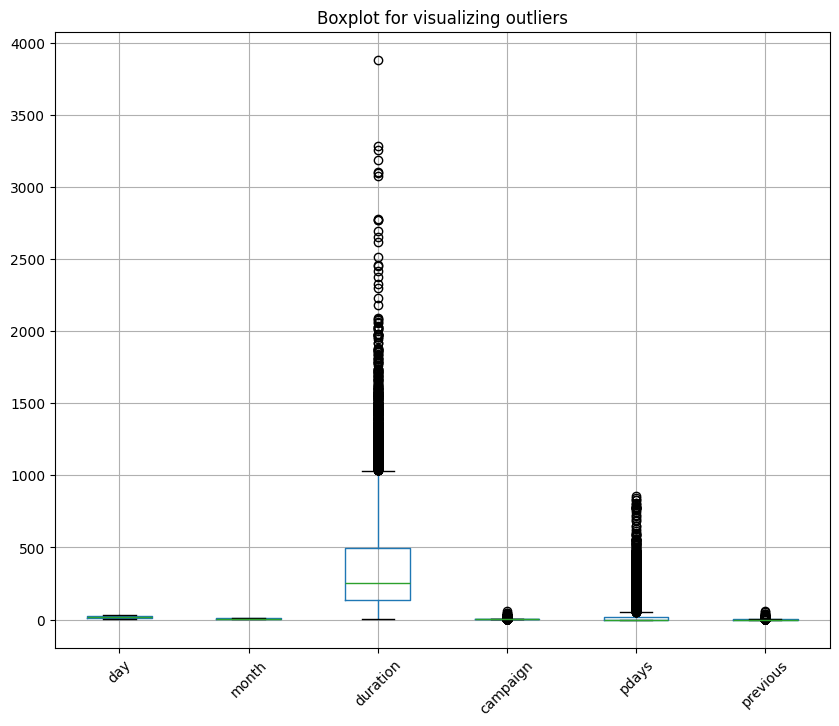

In [183]:
#OUTLIERS

#1. Boxplot to visualize outliers
import matplotlib.pyplot as plt
plt.figure(figsize=(10,8))
df.drop(['deposit','balance','age'],axis=1).boxplot()
plt.xticks(rotation=45)
plt.title("Boxplot for visualizing outliers")
plt.show()

In [184]:
#2. checking number of outliers
num_value=df.drop(['deposit','balance','age'],axis=1).select_dtypes(exclude=object).columns
for out in num_value:
  Q1=df[out].quantile(0.25)
  Q3=df[out].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-1.5*IQR
  upper=Q3+1.5*IQR
  outliers=df[(df[out]<lower)|(df[out]>upper)]
  print(out,"outliers:",len(outliers))

day outliers: 0
month outliers: 0
duration outliers: 636
campaign outliers: 601
pdays outliers: 2750
previous outliers: 1258


In [185]:
#3. treating outliers
for out in num_value:
  Q1=df[out].quantile(0.25)
  Q3=df[out].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-1.5*IQR
  upper=Q3+1.5*IQR
  df[out]=df[out].clip(lower,upper)

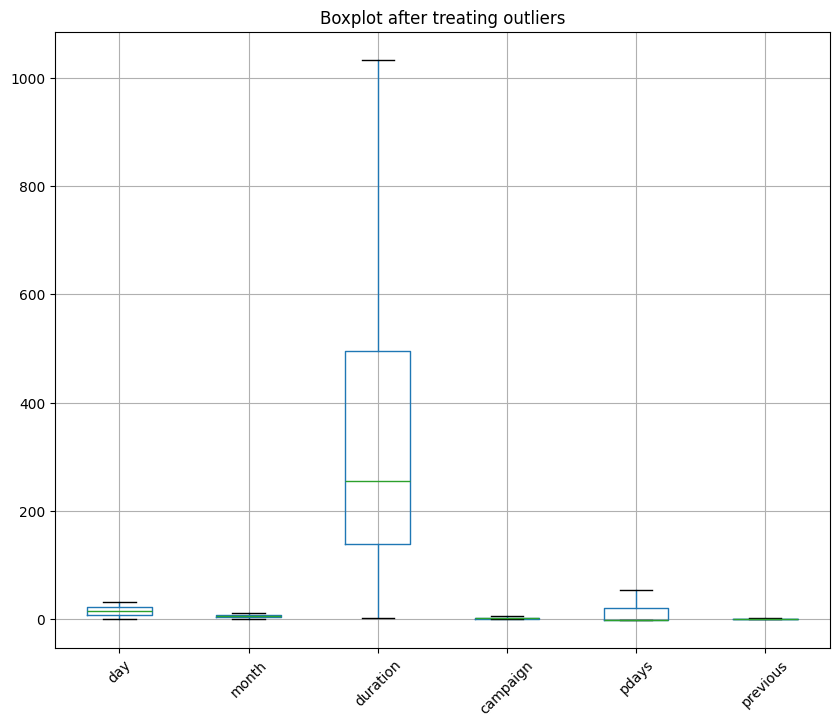

In [186]:
#4. Boxplot after outliers treatment
import matplotlib.pyplot as plt
plt.figure(figsize=(10,8))
df.drop(['deposit','balance','age'],axis=1).boxplot()
plt.xticks(rotation=45)
plt.title("Boxplot after treating outliers")
plt.show()

In [187]:
#ENCODING
obj=df.select_dtypes(include=object).columns
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for ch in obj:
  df[ch]=le.fit_transform(df[ch])
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,0,1,1,0,2343,1,0,2,5,5,1033,1,-1.000,0.0,3,1
1,56,0,1,1,0,45,0,0,2,5,5,1033,1,-1.000,0.0,3,1
2,41,9,1,1,0,1270,1,0,2,5,5,1033,1,-1.000,0.0,3,1
3,55,7,1,1,0,2476,1,0,2,5,5,579,1,-1.000,0.0,3,1
4,54,0,1,2,0,184,0,0,2,5,5,673,2,-1.000,0.0,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,1,2,0,0,1,1,0,0,20,4,257,1,-1.000,0.0,3,0
11158,39,7,1,1,0,733,0,0,2,16,6,83,4,-1.000,0.0,3,0
11159,32,9,2,1,0,29,0,0,0,19,8,156,2,-1.000,0.0,3,0
11160,43,9,1,1,0,0,0,1,0,8,5,9,2,53.375,2.5,0,0


In [188]:
#feature selection
corre=df.corr(numeric_only=True)
print(corre['deposit'].sort_values(ascending=False))

deposit      1.000000
duration     0.492314
pdays        0.231578
previous     0.219674
education    0.095948
balance      0.081129
marital      0.067610
job          0.063395
age          0.034901
month        0.028645
default     -0.040680
day         -0.056326
loan        -0.110580
poutcome    -0.122369
campaign    -0.134689
housing     -0.203888
contact     -0.249847
Name: deposit, dtype: float64


In [189]:
#input output separation
x=df.drop('deposit',axis=1)
y=df['deposit']
print(x.ndim)
print(y.ndim)

2
1


In [190]:
#TRAIN TEST SPLITTING
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(ytrain.shape)
print(xtest.shape)
print(ytest.shape)

(7813, 16)
(7813,)
(3349, 16)
(3349,)


In [191]:
#DATA BALANCING
print(ytrain.value_counts())
from imblearn.over_sampling import SMOTE
sm=SMOTE()
xtrain1,ytrain1=sm.fit_resample(xtrain,ytrain)
print(ytrain1.value_counts())

deposit
0    4100
1    3713
Name: count, dtype: int64
deposit
1    4100
0    4100
Name: count, dtype: int64


In [192]:
#HYPERPARAMETER TUNING FOR DECISION TREE
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
dt_mod=DecisionTreeClassifier(random_state=41)
dt_param={'criterion':['gini','entropy','log_loss'], 'max_depth':[3,5,7,10,None],
          'min_samples_split':[2,3,5],'min_samples_leaf':[1,2,4]}
dt_grid=GridSearchCV(dt_mod,dt_param,cv=3,scoring='accuracy')
#training
dt_grid.fit(xtrain1,ytrain1)
#best performance
dt_grid.best_params_

{'criterion': 'gini',
 'max_depth': 7,
 'min_samples_leaf': 1,
 'min_samples_split': 3}

In [193]:
#DECISION TREE MODEL BUILDING
dt=DecisionTreeClassifier(criterion= 'gini',max_depth=7,min_samples_leaf= 1,min_samples_split= 2)
#model training
dt.fit(xtrain1,ytrain1)
#predicting
dt_ypred=dt.predict(xtest)
dt_ypred

array([0, 0, 0, ..., 1, 0, 1])

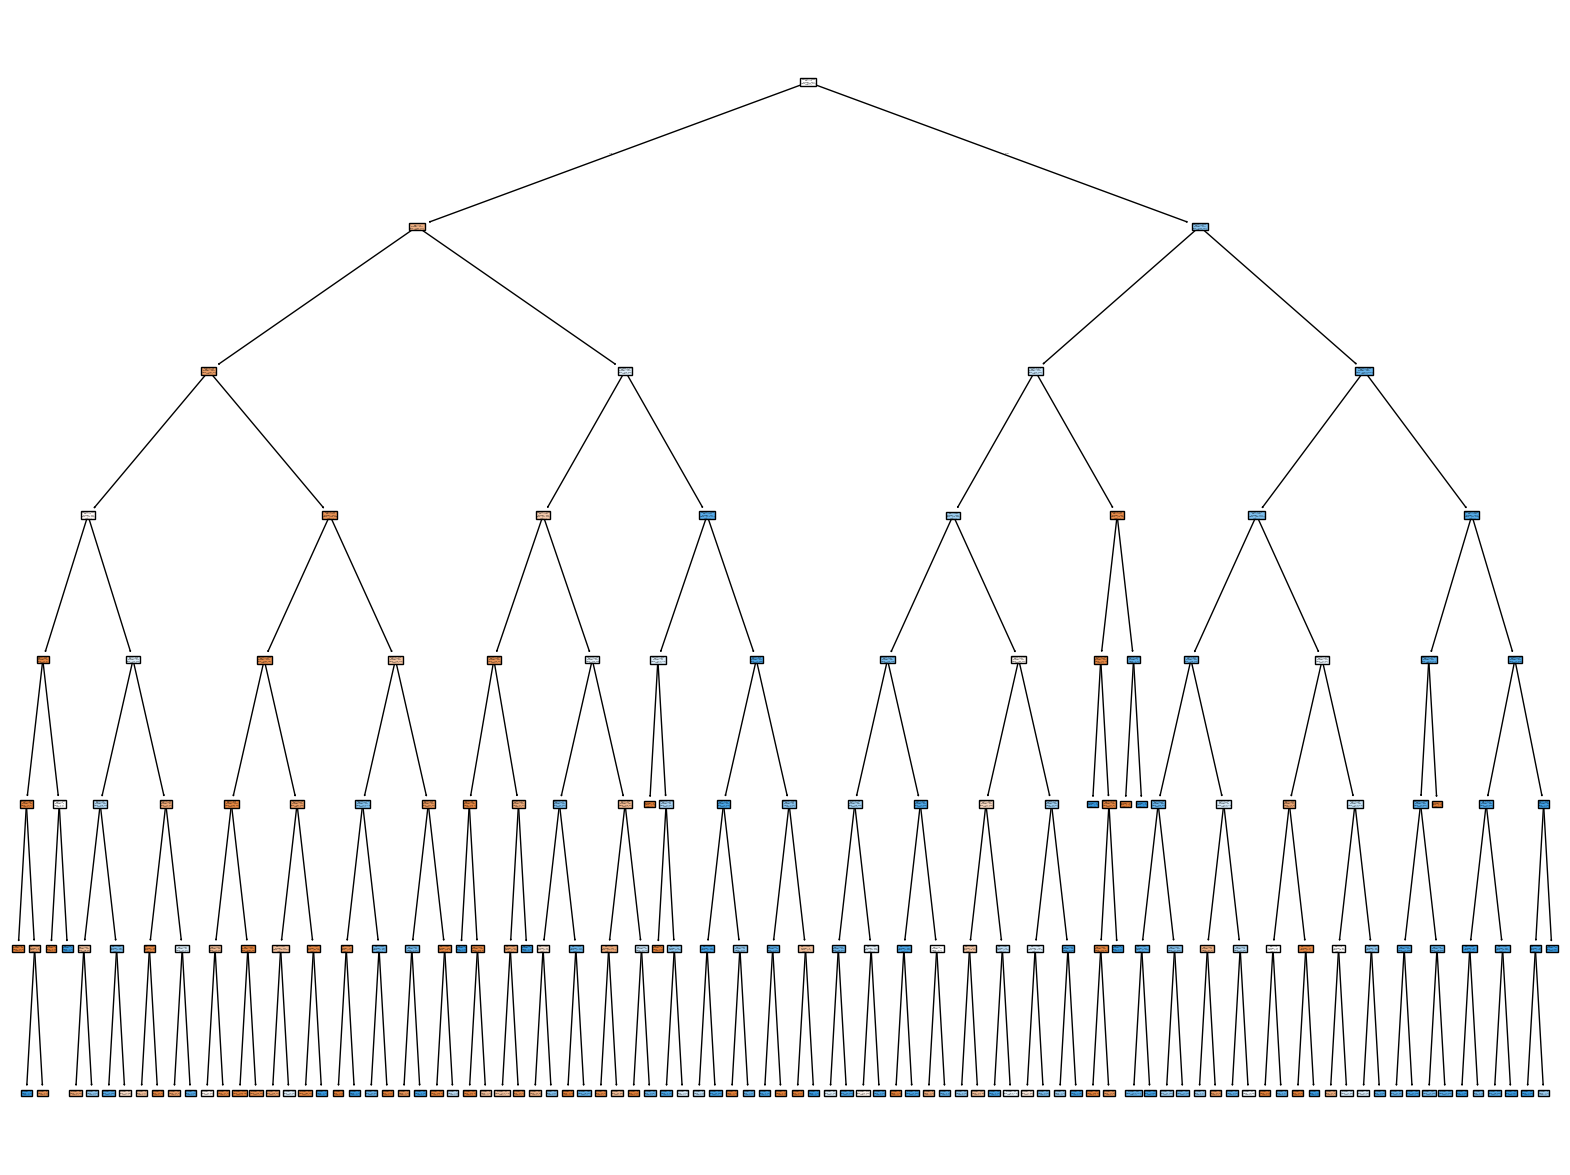

In [194]:
#TREE VISUALIZATION
from sklearn import tree
plt.figure(figsize=(20,15))
tree.plot_tree(dt,feature_names=x.columns,class_names=df.deposit.astype(str).unique(),filled=True)
plt.show()


In [195]:
#HYPERPARAMETER TUNING FOR RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier
rfc_mod=RandomForestClassifier(random_state=41)
rfc_param={'n_estimators':[30,50,90], 'max_depth':[None,10,15],
          'min_samples_split':[2,3,5],'min_samples_leaf':[1,2,4]}
rfc_grid=GridSearchCV(rfc_mod,dt_param,cv=3,scoring='accuracy')
#training
rfc_grid.fit(xtrain1,ytrain1)
#best performance
rfc_grid.best_params_

{'criterion': 'entropy',
 'max_depth': None,
 'min_samples_leaf': 1,
 'min_samples_split': 3}

In [196]:
#RANDOM FOREST MODEL BUILDING
rfc=RandomForestClassifier()
#model training
rfc.fit(xtrain1,ytrain1)
#predicting
rfc_ypred=rfc.predict(xtest)
rfc_ypred

In [197]:
#HYPERPARAMETER TUNING FOR XGBOOST
from xgboost import XGBClassifier
xgb_mod=XGBClassifier(random_state=41)
xgb_param={'n_estimators':[100,200], 'max_depth':[None,10,15,20],
          'learning_rate':[0.01,0.1],'subsample':[0.8,1.0]}
xgb_grid=GridSearchCV(xgb_mod,dt_param,cv=3,scoring='accuracy')
#training
xgb_grid.fit(xtrain1,ytrain1)
#best performance
xgb_grid.best_params_

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:04:15] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "criterion", "min_samples_leaf", "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:04:15] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "criterion", "min_samples_leaf", "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:04:16] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "criterion", "min_samples_leaf", "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:04:16] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "criterion", "min_samples_leaf", "min_samp

{'criterion': 'gini',
 'max_depth': 3,
 'min_samples_leaf': 1,
 'min_samples_split': 2}

In [198]:
#XGBOOST MODEL BUILDING
xgb=XGBClassifier(max_depth=3,min_samples_leaf= 1,min_samples_split= 2)
#model training
xgb.fit(xtrain1,ytrain1)
#predicting
xgb_ypred=xgb.predict(xtest)
xgb_ypred

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:06:00] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_samples_leaf", "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


array([0, 0, 0, ..., 1, 0, 1])

In [199]:
#HYPERPARAMETER TUNING FOR DECISION TREE

In [200]:
#HYPERPARAMETER TUNING FOR DECISION TREE